Selecciona tu archivo de audio original (.ogg, .wav o .mp3)


Saving audio_voz_original.ogg to audio_voz_original.ogg

========== RESULTADOS ==========
Archivo: audio_voz_original.ogg
Frecuencia original: 48000 Hz
Frecuencia de trabajo: 16000 Hz
Duración: 38.27 segundos
Número de muestras: 612376
Canales: Mono
Estado: Audio preparado correctamente


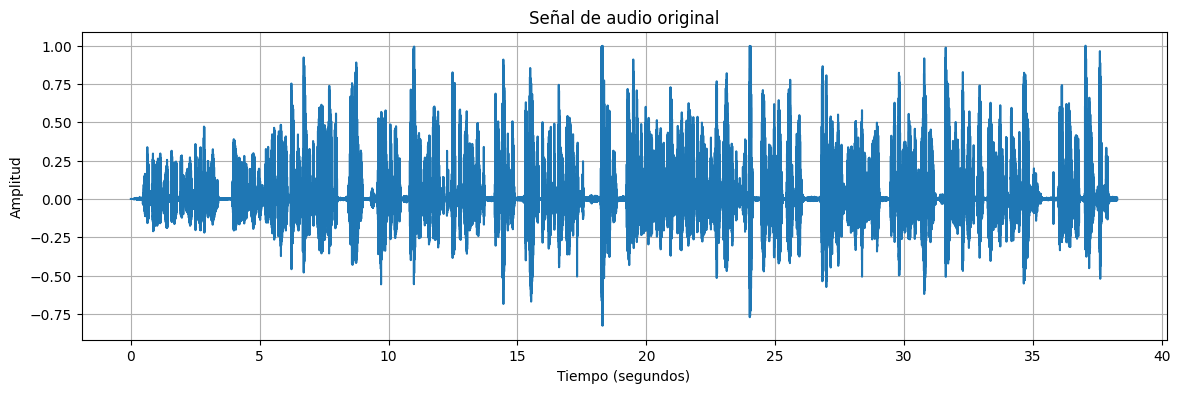

In [ ]:

# ==========================================
# ACTIVIDAD SUMATIVA N.º 4
# EL FILTRO PERFECTO
# Preparación de la señal de audio
# ==========================================

# Instalar las librerías necesarias
!pip install -q librosa soundfile

# Importar librerías
import numpy as np
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
from google.colab import files

# Subir la grabación
print("Selecciona tu archivo de audio original (.ogg, .wav o .mp3)")
uploaded = files.upload()

# Obtener el nombre del archivo
nombre_archivo = next(iter(uploaded.keys()))

# Cargar el audio
audio, frecuencia_original = librosa.load(
    nombre_archivo,
    sr=None,
    mono=True
)

# Convertir la frecuencia de muestreo a 16.000 Hz
frecuencia_muestreo = 16000

audio = librosa.resample(
    audio,
    orig_sr=frecuencia_original,
    target_sr=frecuencia_muestreo
)

# Normalizar la señal
audio = audio / np.max(np.abs(audio))

# Guardar la señal preparada
sf.write("audio_original.wav", audio, frecuencia_muestreo)

# Mostrar información
print("\n========== RESULTADOS ==========")
print("Archivo:", nombre_archivo)
print("Frecuencia original:", frecuencia_original, "Hz")
print("Frecuencia de trabajo:", frecuencia_muestreo, "Hz")
print("Duración:", round(len(audio)/frecuencia_muestreo, 2), "segundos")
print("Número de muestras:", len(audio))
print("Canales: Mono")
print("Estado: Audio preparado correctamente")

# Graficar la señal original
tiempo = np.arange(len(audio)) / frecuencia_muestreo

plt.figure(figsize=(14, 4))
plt.plot(tiempo, audio)
plt.title("Señal de audio original")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()

========== RESULTADOS DEL RUIDO ==========
SNR deseado: 5 dB
SNR real de entrada: 4.99 dB
MSE inicial: 0.003839
Estado: Ruido agregado correctamente


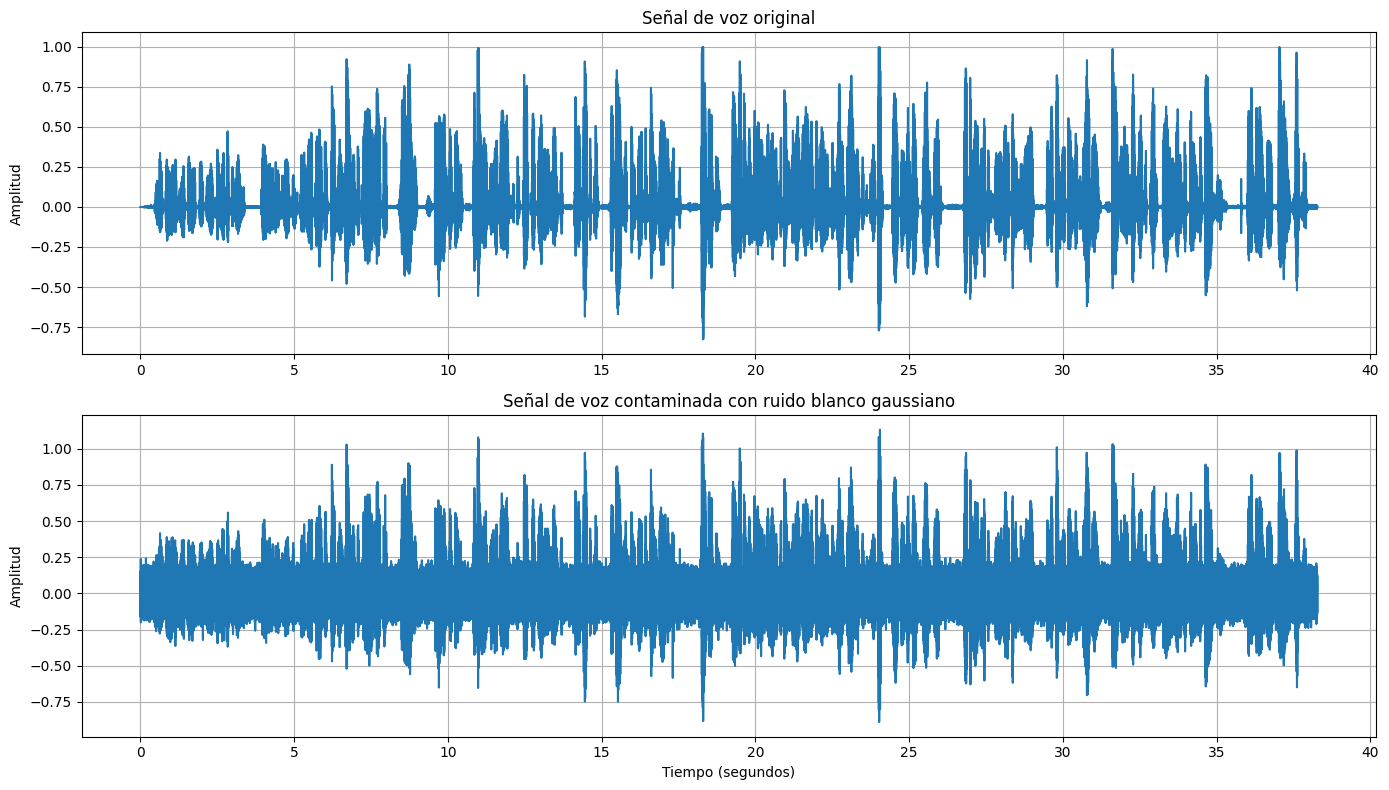

In [ ]:

# ==========================================
# PASO 2: GENERACIÓN DE RUIDO BLANCO GAUSSIANO
# ==========================================

# Establecer una semilla para reproducir el experimento
np.random.seed(42)

# Definir la relación señal-ruido deseada
snr_deseado = 5  # decibelios (dB)

# Calcular la potencia de la señal original
potencia_senal = np.mean(audio ** 2)

# Calcular la potencia del ruido necesaria
potencia_ruido = potencia_senal / (10 ** (snr_deseado / 10))

# Generar ruido blanco gaussiano
ruido = np.random.normal(
    0,
    np.sqrt(potencia_ruido),
    len(audio)
)

# Mezclar la voz original con el ruido
audio_contaminado = audio + ruido

# Calcular el SNR real de entrada
snr_entrada = 10 * np.log10(
    np.mean(audio ** 2) / np.mean(ruido ** 2)
)

# Calcular el error cuadrático medio inicial
mse_entrada = np.mean((audio - audio_contaminado) ** 2)

# Guardar el audio contaminado
sf.write(
    "audio_contaminado.wav",
    audio_contaminado,
    frecuencia_muestreo
)

# Mostrar resultados
print("========== RESULTADOS DEL RUIDO ==========")
print("SNR deseado:", snr_deseado, "dB")
print("SNR real de entrada:", round(snr_entrada, 2), "dB")
print("MSE inicial:", round(mse_entrada, 6))
print("Estado: Ruido agregado correctamente")

# Comparar las señales
plt.figure(figsize=(14, 8))

plt.subplot(2, 1, 1)
plt.plot(tiempo, audio)
plt.title("Señal de voz original")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(tiempo, audio_contaminado)
plt.title("Señal de voz contaminada con ruido blanco gaussiano")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()


========== RESULTADOS DEL FILTRO FIR ==========
Tipo: Pasa-bajos
Orden: 100
Coeficientes: 101
Ventana: Hamming
Frecuencia de corte: 3400 Hz
Retardo compensado: 50 muestras

========== MÉTRICAS ==========
SNR de entrada: 4.99 dB
SNR de salida: 8.61 dB
Mejora del SNR: 3.61 dB
MSE de entrada: 0.003839
MSE de salida: 0.00167


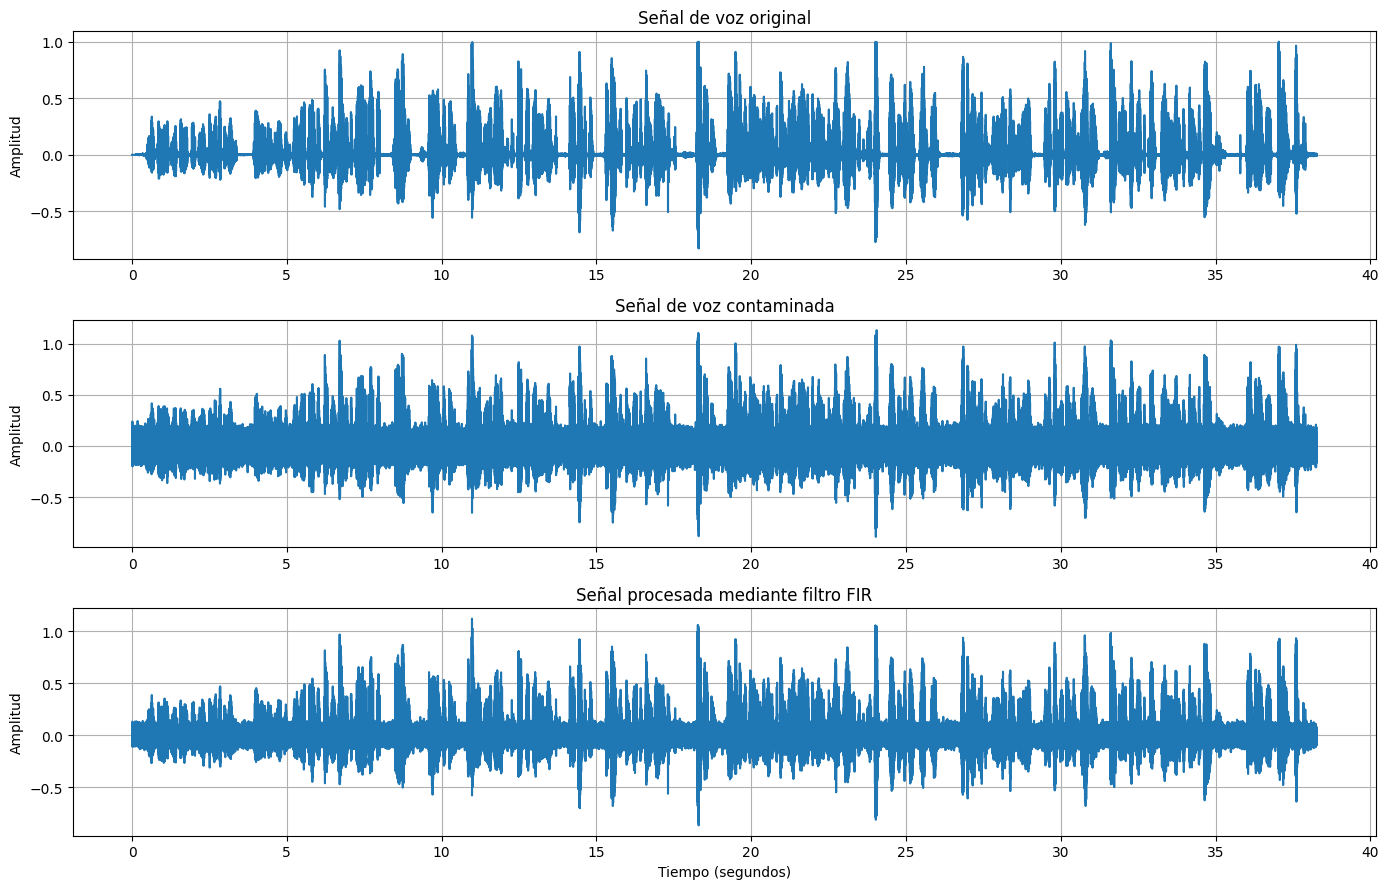

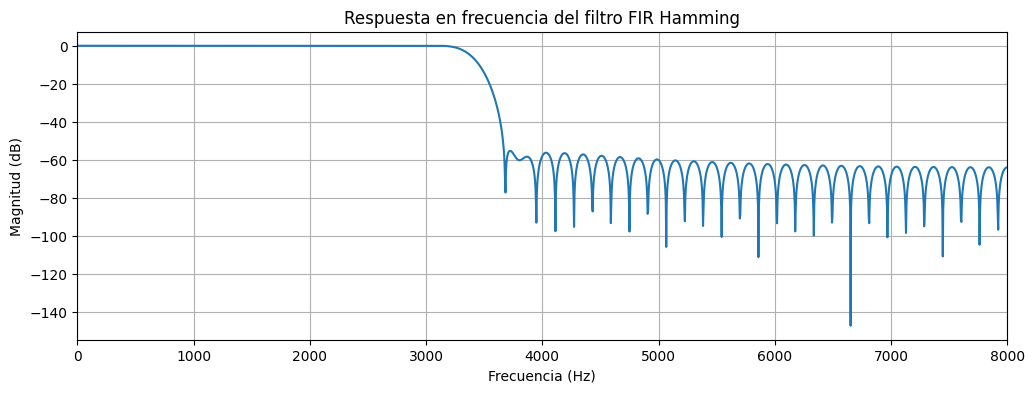

In [ ]:

# ==========================================
# PASO 3: DISEÑO DEL FILTRO DIGITAL FIR
# Ventana Hamming - Filtro pasa-bajos
# ==========================================

from scipy import signal

# Parámetros del filtro
orden_fir = 100
numero_coeficientes = orden_fir + 1
frecuencia_corte = 3400

# Diseñar el filtro FIR mediante ventana Hamming
coeficientes_fir = signal.firwin(
    numtaps=numero_coeficientes,
    cutoff=frecuencia_corte,
    window="hamming",
    pass_zero="lowpass",
    fs=frecuencia_muestreo
)

# Aplicar el filtro a la señal contaminada
audio_fir = signal.lfilter(
    coeficientes_fir,
    [1.0],
    audio_contaminado
)

# Compensar el retardo del filtro FIR
retardo_fir = orden_fir // 2

audio_fir_alineado = audio_fir[retardo_fir:]
audio_limpio_alineado = audio[:-retardo_fir]
audio_ruidoso_alineado = audio_contaminado[:-retardo_fir]

# Calcular métricas sobre las mismas muestras
snr_entrada_fir = 10 * np.log10(
    np.mean(audio_limpio_alineado ** 2) /
    np.mean((audio_ruidoso_alineado - audio_limpio_alineado) ** 2)
)

mse_entrada_fir = np.mean(
    (audio_limpio_alineado - audio_ruidoso_alineado) ** 2
)

snr_salida_fir = 10 * np.log10(
    np.mean(audio_limpio_alineado ** 2) /
    np.mean((audio_limpio_alineado - audio_fir_alineado) ** 2)
)

mse_salida_fir = np.mean(
    (audio_limpio_alineado - audio_fir_alineado) ** 2
)

mejora_snr_fir = snr_salida_fir - snr_entrada_fir

# Guardar el audio filtrado
sf.write(
    "audio_filtrado_FIR.wav",
    audio_fir_alineado,
    frecuencia_muestreo
)

# Mostrar resultados
print("========== RESULTADOS DEL FILTRO FIR ==========")
print("Tipo: Pasa-bajos")
print("Orden:", orden_fir)
print("Coeficientes:", numero_coeficientes)
print("Ventana: Hamming")
print("Frecuencia de corte:", frecuencia_corte, "Hz")
print("Retardo compensado:", retardo_fir, "muestras")

print("\n========== MÉTRICAS ==========")
print("SNR de entrada:", round(snr_entrada_fir, 2), "dB")
print("SNR de salida:", round(snr_salida_fir, 2), "dB")
print("Mejora del SNR:", round(mejora_snr_fir, 2), "dB")
print("MSE de entrada:", round(mse_entrada_fir, 6))
print("MSE de salida:", round(mse_salida_fir, 6))

# Gráficas comparativas
tiempo_fir = np.arange(len(audio_fir_alineado)) / frecuencia_muestreo

plt.figure(figsize=(14, 9))

plt.subplot(3, 1, 1)
plt.plot(tiempo_fir, audio_limpio_alineado)
plt.title("Señal de voz original")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(tiempo_fir, audio_ruidoso_alineado)
plt.title("Señal de voz contaminada")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(tiempo_fir, audio_fir_alineado)
plt.title("Señal procesada mediante filtro FIR")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

# Respuesta en frecuencia del filtro
frecuencias, respuesta = signal.freqz(
    coeficientes_fir,
    worN=2048,
    fs=frecuencia_muestreo
)

plt.figure(figsize=(12, 4))
plt.plot(frecuencias, 20 * np.log10(np.maximum(np.abs(respuesta), 1e-10)))
plt.title("Respuesta en frecuencia del filtro FIR Hamming")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 8000)
plt.grid(True)
plt.show()


In [ ]:
print("¿Existe audio?:", 'audio' in globals())
print("¿Existe frecuencia_muestreo?:", 'frecuencia_muestreo' in globals())

¿Existe audio?: False
¿Existe frecuencia_muestreo?: False


In [ ]:
from google.colab import files
import librosa
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

# Subir nuevamente el audio original
archivos = files.upload()

nombre_archivo = next(iter(archivos))

# Cargar el audio
audio, frecuencia_original = librosa.load(
    nombre_archivo,
    sr=None,
    mono=True
)

# Convertir a 16.000 Hz
frecuencia_muestreo = 16000

audio = librosa.resample(
    audio,
    orig_sr=frecuencia_original,
    target_sr=frecuencia_muestreo
)

# Normalizar
audio = audio / np.max(np.abs(audio))

# Guardar audio preparado
sf.write("audio_original.wav", audio, frecuencia_muestreo)

print("========== AUDIO RECUPERADO ==========")
print("Frecuencia original:", frecuencia_original, "Hz")
print("Frecuencia de trabajo:", frecuencia_muestreo, "Hz")
print("Duración:", len(audio) / frecuencia_muestreo, "segundos")
print("Número de muestras:", len(audio))

Saving audio_voz_original.ogg to audio_voz_original.ogg
========== AUDIO RECUPERADO ==========
Frecuencia original: 48000 Hz
Frecuencia de trabajo: 16000 Hz
Duración: 38.2735 segundos
Número de muestras: 612376


========== RESULTADOS DEL FILTRO LMS ==========
Tipo: Filtro adaptativo LMS
Frecuencia de muestreo: 16000 Hz
Longitud del filtro: 16
Número de coeficientes: 16
Parámetro de adaptación: 1.0699442821947374

========== MÉTRICAS ==========
SNR de entrada: 5.09 dB
SNR de salida: 16.23 dB
Mejora del SNR: 11.14 dB
MSE de entrada: 0.003834
MSE de salida: 0.000295

Archivo generado: audio_filtrado_LMS.wav


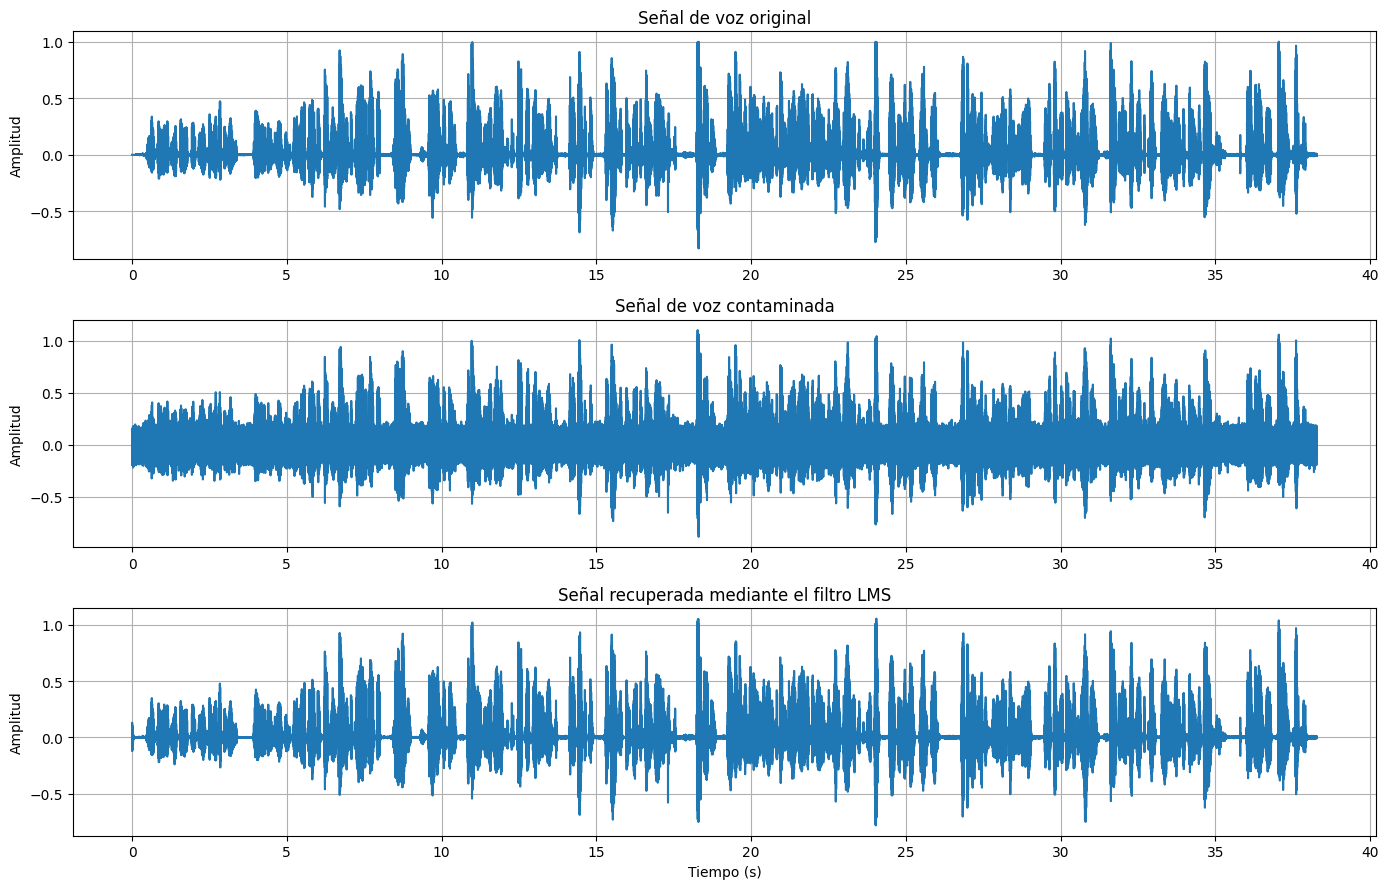

In [ ]:

# ============================================================
# PASO 4: FILTRO ADAPTATIVO LMS
# ============================================================

from scipy import signal
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. GENERACIÓN DEL RUIDO Y SEÑAL DE REFERENCIA
# ------------------------------------------------------------

generador = np.random.default_rng(123)

# Fuente común de ruido blanco gaussiano
fuente_ruido = generador.normal(0, 1, len(audio))

# Canal que contamina la señal de voz
canal_primario = [1.0, 0.5, 0.25]

ruido_sin_escalar = signal.lfilter(
    canal_primario,
    [1.0],
    fuente_ruido
)

# Ajustar el ruido para obtener una SNR de 5 dB
snr_deseado = 5

potencia_voz = np.mean(audio ** 2)
potencia_ruido_objetivo = (
    potencia_voz / (10 ** (snr_deseado / 10))
)

factor_escala = np.sqrt(
    potencia_ruido_objetivo /
    np.mean(ruido_sin_escalar ** 2)
)

ruido_lms = ruido_sin_escalar * factor_escala

# Referencia captada por un segundo canal
referencia_lms = fuente_ruido * factor_escala

# Señal de voz contaminada
audio_contaminado_lms = audio + ruido_lms


# ------------------------------------------------------------
# 2. CONFIGURACIÓN DEL FILTRO LMS
# ------------------------------------------------------------

longitud_lms = 16

potencia_referencia = np.mean(referencia_lms ** 2)

mu_lms = 0.05 / (
    longitud_lms * potencia_referencia
)

pesos_lms = np.zeros(longitud_lms)

estimacion_ruido_lms = np.zeros(len(audio))
audio_filtrado_lms = np.zeros(len(audio))


# ------------------------------------------------------------
# 3. PROCESAMIENTO MEDIANTE EL ALGORITMO LMS
# ------------------------------------------------------------

for n in range(longitud_lms - 1, len(audio)):

    vector_entrada = referencia_lms[
        n - longitud_lms + 1:n + 1
    ][::-1]

    estimacion = np.dot(pesos_lms, vector_entrada)

    error = audio_contaminado_lms[n] - estimacion

    # Actualización adaptativa de los coeficientes
    pesos_lms += mu_lms * error * vector_entrada

    estimacion_ruido_lms[n] = estimacion
    audio_filtrado_lms[n] = error


# ------------------------------------------------------------
# 4. CÁLCULO DE MÉTRICAS
# ------------------------------------------------------------

# Evaluación desde el segundo segundo
inicio = frecuencia_muestreo

voz_eval = audio[inicio:]
ruido_eval = ruido_lms[inicio:]
entrada_eval = audio_contaminado_lms[inicio:]
salida_eval = audio_filtrado_lms[inicio:]

# SNR de entrada
snr_entrada_lms = 10 * np.log10(
    np.mean(voz_eval ** 2) /
    np.mean(ruido_eval ** 2)
)

# SNR de salida
snr_salida_lms = 10 * np.log10(
    np.mean(voz_eval ** 2) /
    np.mean((voz_eval - salida_eval) ** 2)
)

# Mejora del SNR
mejora_snr_lms = snr_salida_lms - snr_entrada_lms

# MSE de entrada
mse_entrada_lms = np.mean(
    (voz_eval - entrada_eval) ** 2
)

# MSE de salida
mse_salida_lms = np.mean(
    (voz_eval - salida_eval) ** 2
)


# ------------------------------------------------------------
# 5. PRESENTACIÓN DE RESULTADOS
# ------------------------------------------------------------

print("========== RESULTADOS DEL FILTRO LMS ==========")
print("Tipo: Filtro adaptativo LMS")
print("Frecuencia de muestreo:", frecuencia_muestreo, "Hz")
print("Longitud del filtro:", longitud_lms)
print("Número de coeficientes:", longitud_lms)
print("Parámetro de adaptación:", mu_lms)

print("\n========== MÉTRICAS ==========")
print(f"SNR de entrada: {snr_entrada_lms:.2f} dB")
print(f"SNR de salida: {snr_salida_lms:.2f} dB")
print(f"Mejora del SNR: {mejora_snr_lms:.2f} dB")
print(f"MSE de entrada: {mse_entrada_lms:.6f}")
print(f"MSE de salida: {mse_salida_lms:.6f}")


# ------------------------------------------------------------
# 6. GUARDAR AUDIO FILTRADO
# ------------------------------------------------------------

sf.write(
    "audio_filtrado_LMS.wav",
    audio_filtrado_lms,
    frecuencia_muestreo
)

print("\nArchivo generado: audio_filtrado_LMS.wav")


# ------------------------------------------------------------
# 7. GRÁFICAS DE LAS SEÑALES
# ------------------------------------------------------------

tiempo = np.arange(len(audio)) / frecuencia_muestreo

plt.figure(figsize=(14, 9))

plt.subplot(3, 1, 1)
plt.plot(tiempo, audio)
plt.title("Señal de voz original")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(tiempo, audio_contaminado_lms)
plt.title("Señal de voz contaminada")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(tiempo, audio_filtrado_lms)
plt.title("Señal recuperada mediante el filtro LMS")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()

plt.tight_layout()
plt.show()


 COMPARACIÓN EXPERIMENTAL FIR VS. LMS

Condiciones experimentales:
Frecuencia de muestreo: 16000 Hz
SNR deseado de entrada: 5 dB
Orden FIR: 100
Coeficientes FIR: 101
Longitud LMS: 16
Coeficientes LMS: 16
Parámetro LMS: 1.0699442821947374
Evaluación: mismo intervalo temporal

========== RESULTADOS FIR ==========
SNR de entrada: 5.09 dB
SNR de salida: 6.28 dB
Mejora SNR: 1.19 dB
MSE de entrada: 0.003834
MSE de salida: 0.002913

========== RESULTADOS LMS ==========
SNR de entrada: 5.09 dB
SNR de salida: 16.23 dB
Mejora SNR: 11.14 dB
MSE de entrada: 0.003834
MSE de salida: 0.000295

========== COMPARACIÓN FINAL ==========
Mayor mejora de SNR: LMS
Menor MSE: LMS

Audios comparativos guardados correctamente.


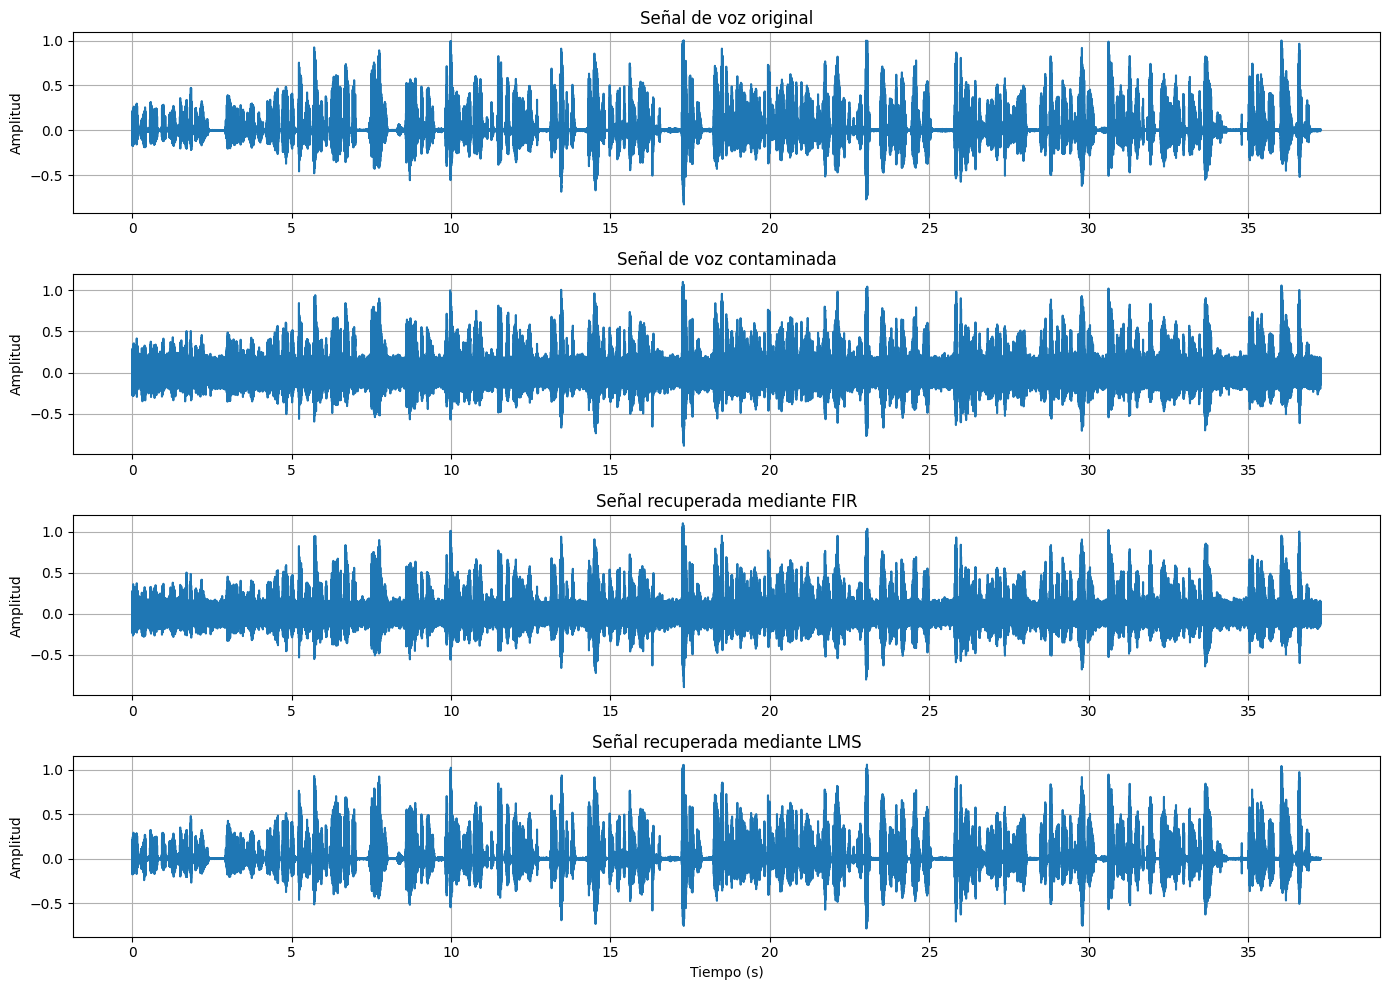

In [ ]:

# ============================================================
# PASO 5: COMPARACIÓN EXPERIMENTAL FIR VS. LMS
# Ambos filtros procesan exactamente la misma señal.
# ============================================================

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal

# ------------------------------------------------------------
# 1. GENERAR UNA ÚNICA SEÑAL CONTAMINADA
# ------------------------------------------------------------

generador_comparacion = np.random.default_rng(123)

fuente_ruido = generador_comparacion.normal(
    0, 1, len(audio)
)

canal_primario = [1.0, 0.5, 0.25]

ruido_sin_escalar = signal.lfilter(
    canal_primario,
    [1.0],
    fuente_ruido
)

snr_deseado = 5

potencia_voz = np.mean(audio ** 2)

potencia_ruido_objetivo = (
    potencia_voz / (10 ** (snr_deseado / 10))
)

factor_escala = np.sqrt(
    potencia_ruido_objetivo /
    np.mean(ruido_sin_escalar ** 2)
)

ruido_comparacion = ruido_sin_escalar * factor_escala

audio_contaminado_comparacion = (
    audio + ruido_comparacion
)

referencia_comparacion = fuente_ruido * factor_escala


# ------------------------------------------------------------
# 2. PROCESAMIENTO MEDIANTE FIR
# ------------------------------------------------------------

orden_fir = 100
numero_coeficientes = orden_fir + 1
frecuencia_corte = 3400

coeficientes_fir = signal.firwin(
    numtaps=numero_coeficientes,
    cutoff=frecuencia_corte,
    window="hamming",
    pass_zero="lowpass",
    fs=frecuencia_muestreo
)

salida_fir = signal.lfilter(
    coeficientes_fir,
    [1.0],
    audio_contaminado_comparacion
)

retardo_fir = orden_fir // 2


# ------------------------------------------------------------
# 3. PROCESAMIENTO MEDIANTE LMS
# ------------------------------------------------------------

longitud_lms = 16

potencia_referencia = np.mean(
    referencia_comparacion ** 2
)

mu_lms = 0.05 / (
    longitud_lms * potencia_referencia
)

pesos_lms = np.zeros(longitud_lms)

salida_lms = np.zeros(len(audio))

for n in range(longitud_lms - 1, len(audio)):

    vector_entrada = referencia_comparacion[
        n - longitud_lms + 1:n + 1
    ][::-1]

    estimacion_ruido = np.dot(
        pesos_lms,
        vector_entrada
    )

    error = (
        audio_contaminado_comparacion[n]
        - estimacion_ruido
    )

    pesos_lms += (
        mu_lms * error * vector_entrada
    )

    salida_lms[n] = error


# ------------------------------------------------------------
# 4. ALINEACIÓN TEMPORAL
# ------------------------------------------------------------

# Ambos resultados se comparan sobre las mismas muestras.
# Se compensa el retardo del filtro FIR.

inicio = frecuencia_muestreo

fin = len(audio) - retardo_fir

voz_referencia = audio[inicio:fin]

senal_entrada = audio_contaminado_comparacion[inicio:fin]

senal_fir = salida_fir[
    inicio + retardo_fir:
    fin + retardo_fir
]

senal_lms = salida_lms[inicio:fin]

ruido_referencia = ruido_comparacion[inicio:fin]


# ------------------------------------------------------------
# 5. CÁLCULO DE MÉTRICAS
# ------------------------------------------------------------

def calcular_metricas(referencia, entrada, salida):

    error_entrada = entrada - referencia
    error_salida = salida - referencia

    snr_entrada = 10 * np.log10(
        np.mean(referencia ** 2) /
        np.mean(error_entrada ** 2)
    )

    snr_salida = 10 * np.log10(
        np.mean(referencia ** 2) /
        np.mean(error_salida ** 2)
    )

    mejora_snr = snr_salida - snr_entrada

    mse_entrada = np.mean(error_entrada ** 2)

    mse_salida = np.mean(error_salida ** 2)

    return (
        snr_entrada,
        snr_salida,
        mejora_snr,
        mse_entrada,
        mse_salida
    )


metricas_fir = calcular_metricas(
    voz_referencia,
    senal_entrada,
    senal_fir
)

metricas_lms = calcular_metricas(
    voz_referencia,
    senal_entrada,
    senal_lms
)


# ------------------------------------------------------------
# 6. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("==============================================")
print(" COMPARACIÓN EXPERIMENTAL FIR VS. LMS")
print("==============================================")

print("\nCondiciones experimentales:")
print("Frecuencia de muestreo:", frecuencia_muestreo, "Hz")
print("SNR deseado de entrada:", snr_deseado, "dB")
print("Orden FIR:", orden_fir)
print("Coeficientes FIR:", numero_coeficientes)
print("Longitud LMS:", longitud_lms)
print("Coeficientes LMS:", longitud_lms)
print("Parámetro LMS:", mu_lms)
print("Evaluación: mismo intervalo temporal")

print("\n========== RESULTADOS FIR ==========")
print(f"SNR de entrada: {metricas_fir[0]:.2f} dB")
print(f"SNR de salida: {metricas_fir[1]:.2f} dB")
print(f"Mejora SNR: {metricas_fir[2]:.2f} dB")
print(f"MSE de entrada: {metricas_fir[3]:.6f}")
print(f"MSE de salida: {metricas_fir[4]:.6f}")

print("\n========== RESULTADOS LMS ==========")
print(f"SNR de entrada: {metricas_lms[0]:.2f} dB")
print(f"SNR de salida: {metricas_lms[1]:.2f} dB")
print(f"Mejora SNR: {metricas_lms[2]:.2f} dB")
print(f"MSE de entrada: {metricas_lms[3]:.6f}")
print(f"MSE de salida: {metricas_lms[4]:.6f}")

print("\n========== COMPARACIÓN FINAL ==========")

if metricas_fir[2] > metricas_lms[2]:
    print("Mayor mejora de SNR: FIR")
elif metricas_lms[2] > metricas_fir[2]:
    print("Mayor mejora de SNR: LMS")
else:
    print("Ambos filtros presentan la misma mejora de SNR.")

if metricas_fir[4] < metricas_lms[4]:
    print("Menor MSE: FIR")
elif metricas_lms[4] < metricas_fir[4]:
    print("Menor MSE: LMS")
else:
    print("Ambos filtros presentan el mismo MSE.")


# ------------------------------------------------------------
# 7. GUARDAR LOS AUDIOS COMPARATIVOS
# ------------------------------------------------------------

sf.write(
    "comparacion_FIR.wav",
    senal_fir,
    frecuencia_muestreo
)

sf.write(
    "comparacion_LMS.wav",
    senal_lms,
    frecuencia_muestreo
)

print("\nAudios comparativos guardados correctamente.")


# ------------------------------------------------------------
# 8. GRÁFICAS COMPARATIVAS
# ------------------------------------------------------------

tiempo = np.arange(len(voz_referencia)) / frecuencia_muestreo

plt.figure(figsize=(14, 10))

plt.subplot(4, 1, 1)
plt.plot(tiempo, voz_referencia)
plt.title("Señal de voz original")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(4, 1, 2)
plt.plot(tiempo, senal_entrada)
plt.title("Señal de voz contaminada")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(4, 1, 3)
plt.plot(tiempo, senal_fir)
plt.title("Señal recuperada mediante FIR")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(4, 1, 4)
plt.plot(tiempo, senal_lms)
plt.title("Señal recuperada mediante LMS")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# PASO 6: COMPLEJIDAD COMPUTACIONAL FIR VS. LMS
# ============================================================
import time
import numpy as np
from scipy import signal

repeticiones = 5

# --- Tiempo FIR ---
tiempos_fir = []
for _ in range(repeticiones):
    t0 = time.perf_counter()
    _ = signal.lfilter(coeficientes_fir, [1.0], audio_contaminado_comparacion)
    tiempos_fir.append(time.perf_counter() - t0)

# --- Tiempo LMS (misma implementación del Paso 5) ---
def ejecutar_lms(ref, entrada, longitud, mu):
    pesos = np.zeros(longitud)
    salida = np.zeros(len(entrada))
    for n in range(longitud - 1, len(entrada)):
        x = ref[n - longitud + 1:n + 1][::-1]
        est = np.dot(pesos, x)
        e = entrada[n] - est
        pesos += mu * e * x
        salida[n] = e
    return salida

tiempos_lms = []
for _ in range(repeticiones):
    t0 = time.perf_counter()
    _ = ejecutar_lms(referencia_comparacion,
                     audio_contaminado_comparacion,
                     longitud_lms, mu_lms)
    tiempos_lms.append(time.perf_counter() - t0)

N = len(audio)
print("========== COMPLEJIDAD COMPUTACIONAL ==========")
print("Muestras procesadas:", N)
print("Repeticiones:", repeticiones)
print(f"\nFIR  - coeficientes: {numero_coeficientes}")
print(f"FIR  - tiempo promedio: {np.mean(tiempos_fir):.4f} s (desv. {np.std(tiempos_fir):.4f})")
print(f"FIR  - multiplicaciones por muestra: {numero_coeficientes}")
print(f"\nLMS  - coeficientes: {longitud_lms}")
print(f"LMS  - tiempo promedio: {np.mean(tiempos_lms):.4f} s (desv. {np.std(tiempos_lms):.4f})")
print(f"LMS  - multiplicaciones por muestra: {2 * longitud_lms} (aprox.)")
print(f"\nRelación de tiempos LMS/FIR: {np.mean(tiempos_lms)/np.mean(tiempos_fir):.1f}x")

========== COMPLEJIDAD COMPUTACIONAL ==========
Muestras procesadas: 612376
Repeticiones: 5

FIR  - coeficientes: 101
FIR  - tiempo promedio: 0.0223 s (desv. 0.0009)
FIR  - multiplicaciones por muestra: 101

LMS  - coeficientes: 16
LMS  - tiempo promedio: 3.2051 s (desv. 0.3399)
LMS  - multiplicaciones por muestra: 32 (aprox.)

Relación de tiempos LMS/FIR: 143.4x


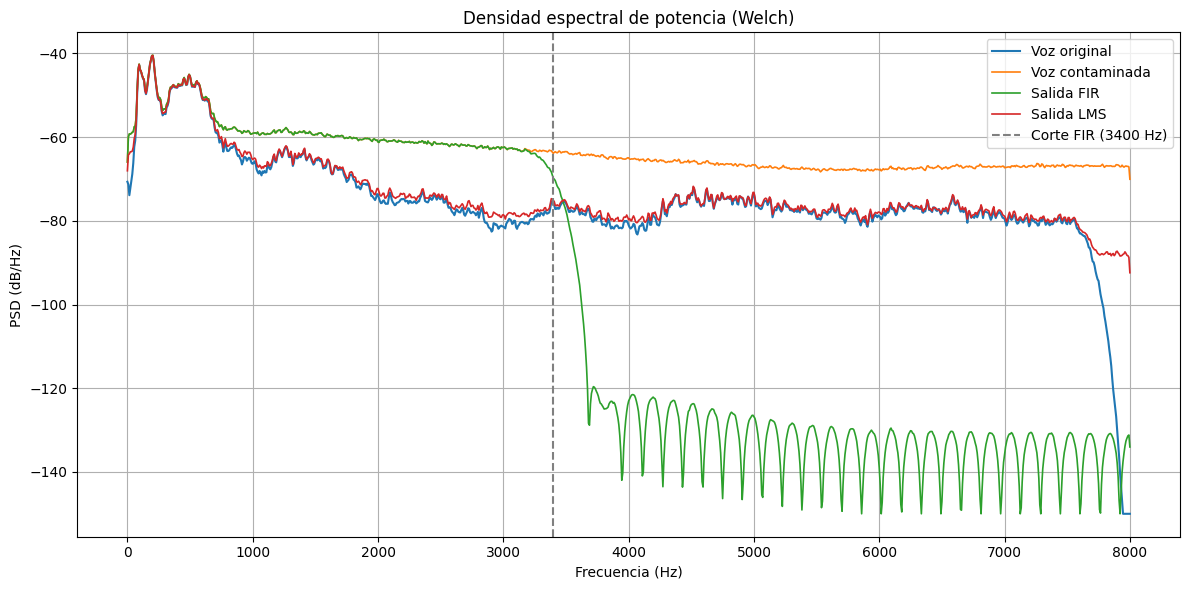

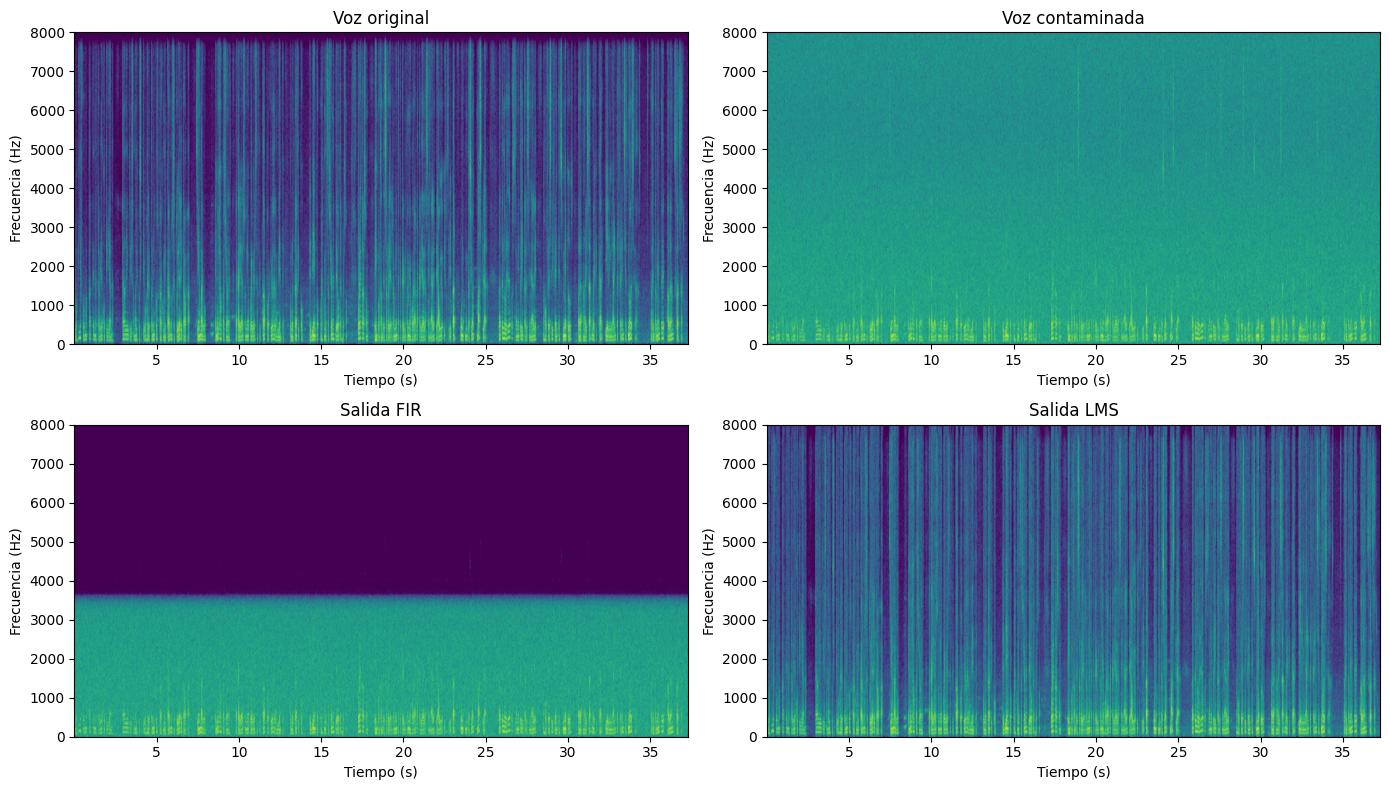

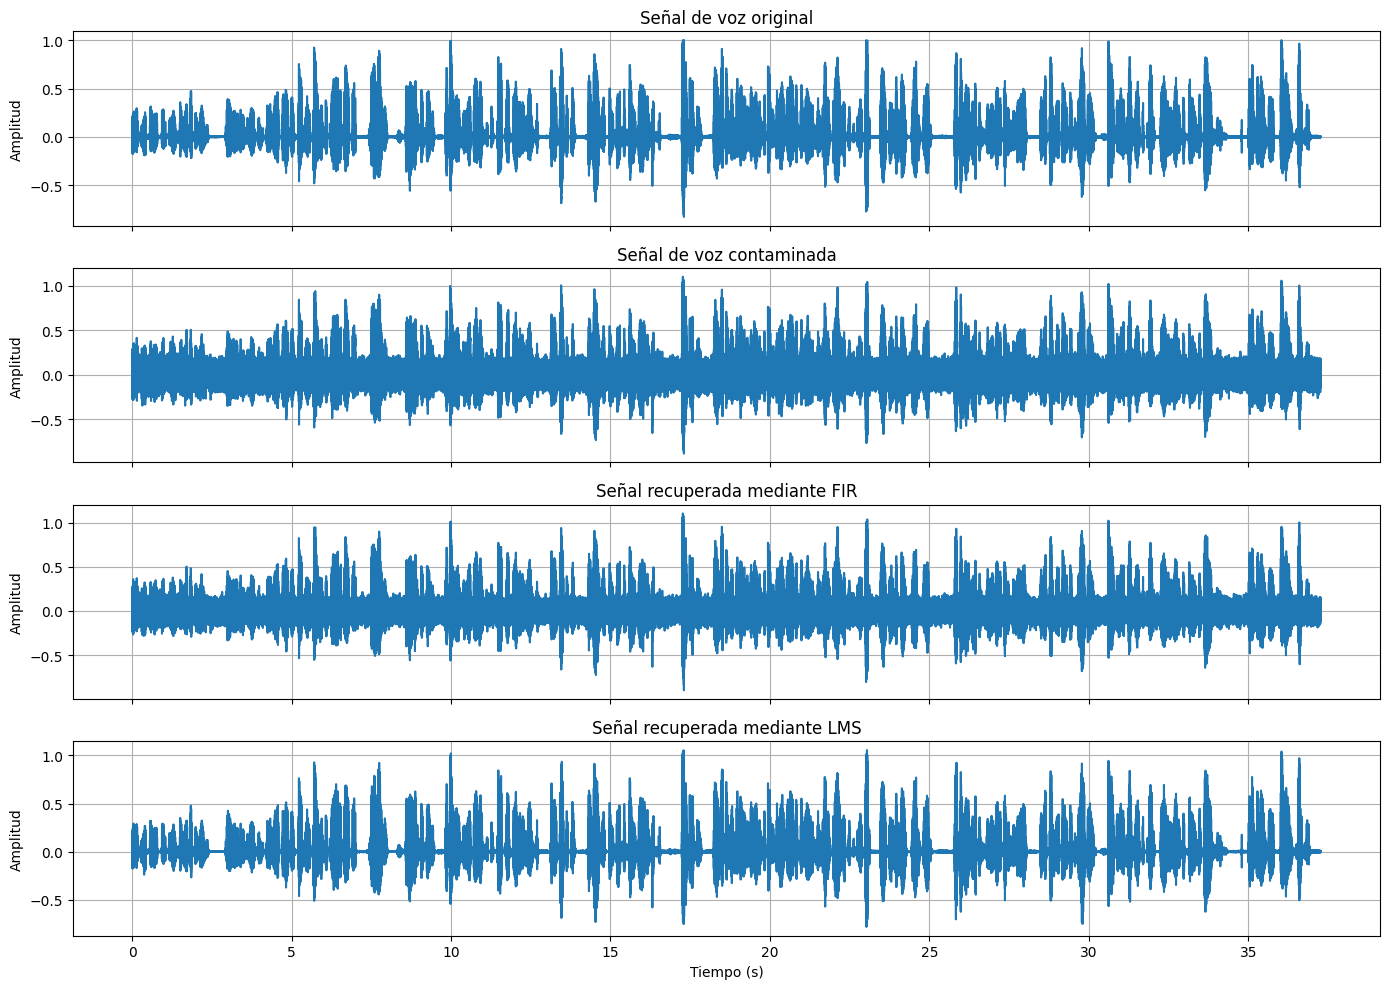

Archivos guardados: espectros_frecuencia.png, espectrogramas.png, comparacion_filtros.png


In [ ]:
# ============================================================
# PASO 7: ANÁLISIS ESPECTRAL Y GUARDADO DE EVIDENCIAS
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

def psd_db(x):
    f, p = signal.welch(x, fs=frecuencia_muestreo, nperseg=2048)
    return f, 10 * np.log10(np.maximum(p, 1e-15))

f1, p_orig = psd_db(voz_referencia)
f2, p_cont = psd_db(senal_entrada)
f3, p_fir  = psd_db(senal_fir)
f4, p_lms  = psd_db(senal_lms)

# --- Gráfica 1: las cuatro señales superpuestas ---
plt.figure(figsize=(12, 6))
plt.plot(f1, p_orig, label="Voz original", linewidth=1.5)
plt.plot(f2, p_cont, label="Voz contaminada", linewidth=1.2)
plt.plot(f3, p_fir,  label="Salida FIR", linewidth=1.2)
plt.plot(f4, p_lms,  label="Salida LMS", linewidth=1.2)
plt.axvline(3400, color="gray", linestyle="--", label="Corte FIR (3400 Hz)")
plt.title("Densidad espectral de potencia (Welch)")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("PSD (dB/Hz)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("espectros_frecuencia.png", dpi=200)
plt.show()

# --- Gráfica 2: espectrogramas ---
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
conjuntos = [
    (voz_referencia, "Voz original"),
    (senal_entrada,  "Voz contaminada"),
    (senal_fir,      "Salida FIR"),
    (senal_lms,      "Salida LMS"),
]
for ax, (x, titulo) in zip(ejes.ravel(), conjuntos):
    ax.specgram(x, NFFT=512, Fs=frecuencia_muestreo, noverlap=256,
                cmap="viridis", vmin=-120, vmax=-20)
    ax.set_title(titulo)
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Frecuencia (Hz)")
plt.tight_layout()
plt.savefig("espectrogramas.png", dpi=200)
plt.show()

# --- Guardar la gráfica temporal de cuatro señales ---
tiempo = np.arange(len(voz_referencia)) / frecuencia_muestreo
fig, ejes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (x, titulo) in zip(ejes, [
    (voz_referencia, "Señal de voz original"),
    (senal_entrada,  "Señal de voz contaminada"),
    (senal_fir,      "Señal recuperada mediante FIR"),
    (senal_lms,      "Señal recuperada mediante LMS"),
]):
    ax.plot(tiempo, x)
    ax.set_title(titulo)
    ax.set_ylabel("Amplitud")
    ax.grid(True)
ejes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.savefig("comparacion_filtros.png", dpi=200)
plt.show()

print("Archivos guardados: espectros_frecuencia.png, espectrogramas.png, comparacion_filtros.png")

Saving audio_voz_original.ogg to audio_voz_original.ogg
========== AUDIO ==========
Archivo: audio_voz_original.ogg | fs original: 48000 Hz | fs trabajo: 16000 Hz
Duración: 38.2735 s | Muestras: 612376 (original: 612376)


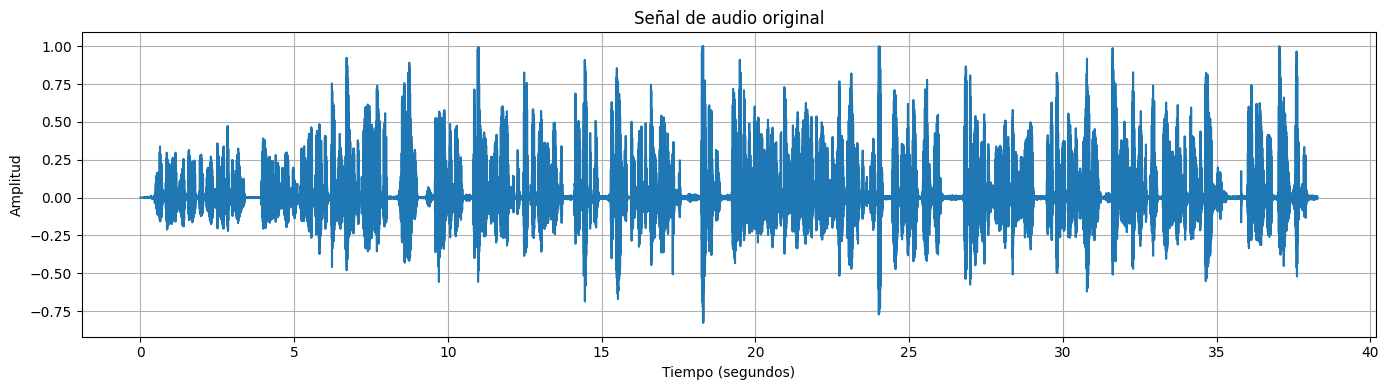


========== RUIDO BLANCO GAUSSIANO (prueba 1) ==========
SNR real de entrada: 4.99 dB
MSE inicial: 0.003839


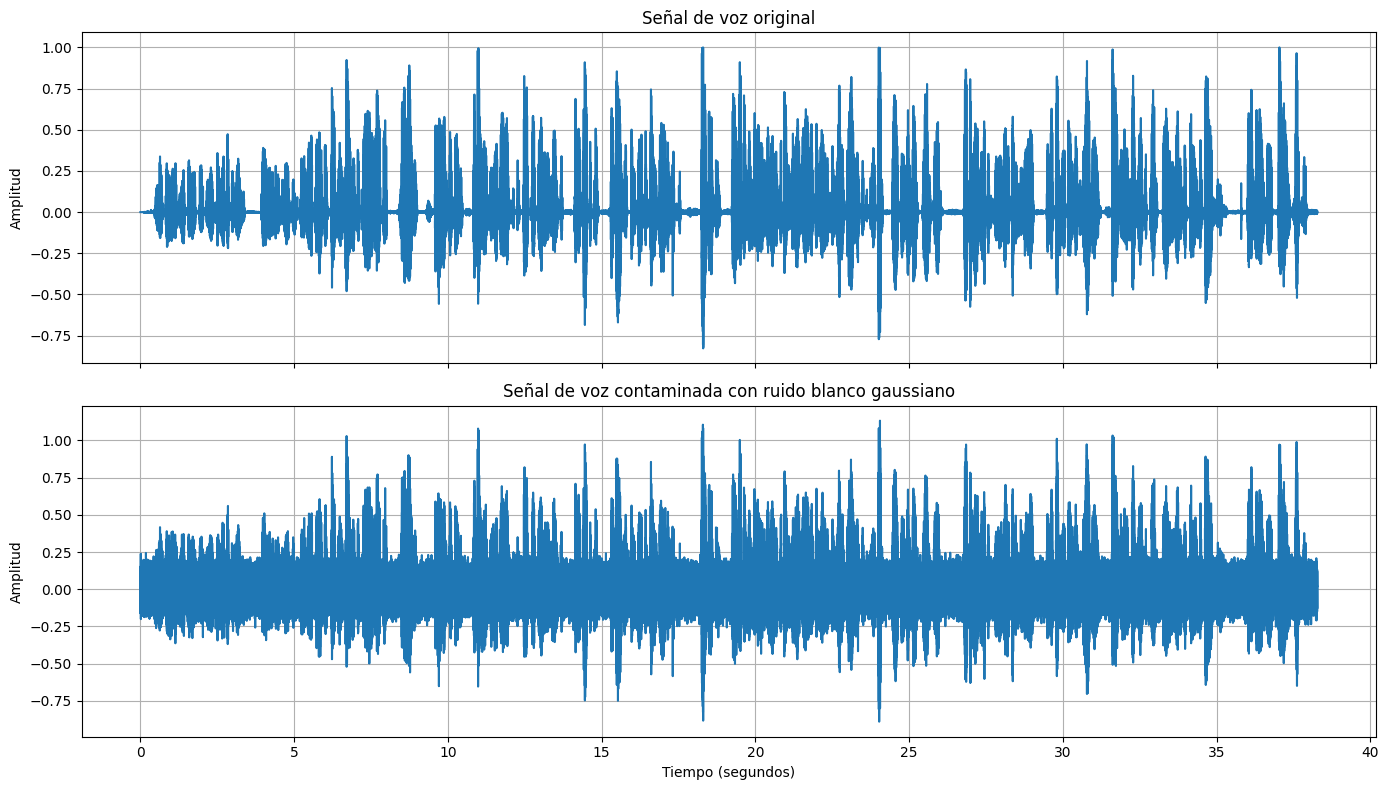


========== FILTRO FIR (prueba 1) ==========
Orden 100 | 101 coef. | Hamming | fc 3400 Hz | retardo 50 muestras
SNR entrada: 4.99 dB | SNR salida: 8.61 dB | Mejora: 3.61 dB
MSE entrada: 0.003839 | MSE salida: 0.001670


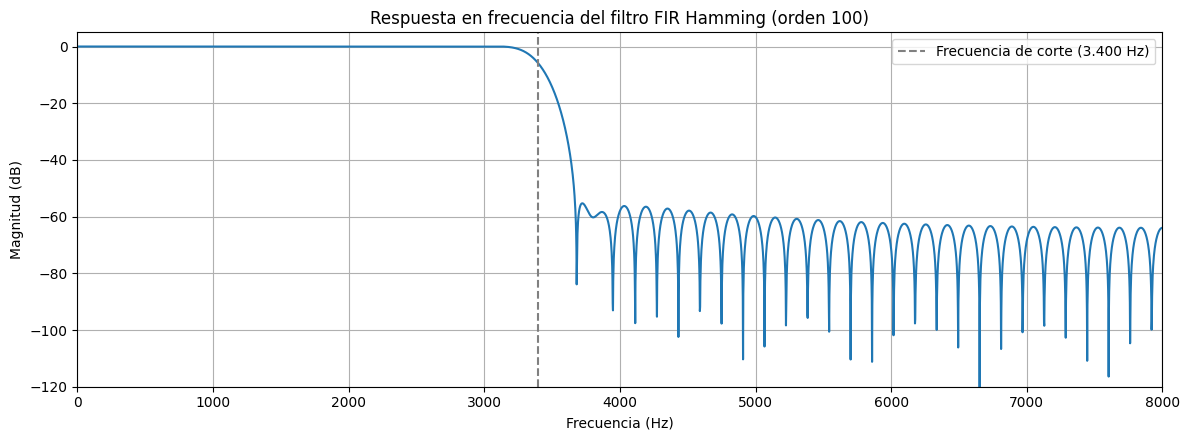

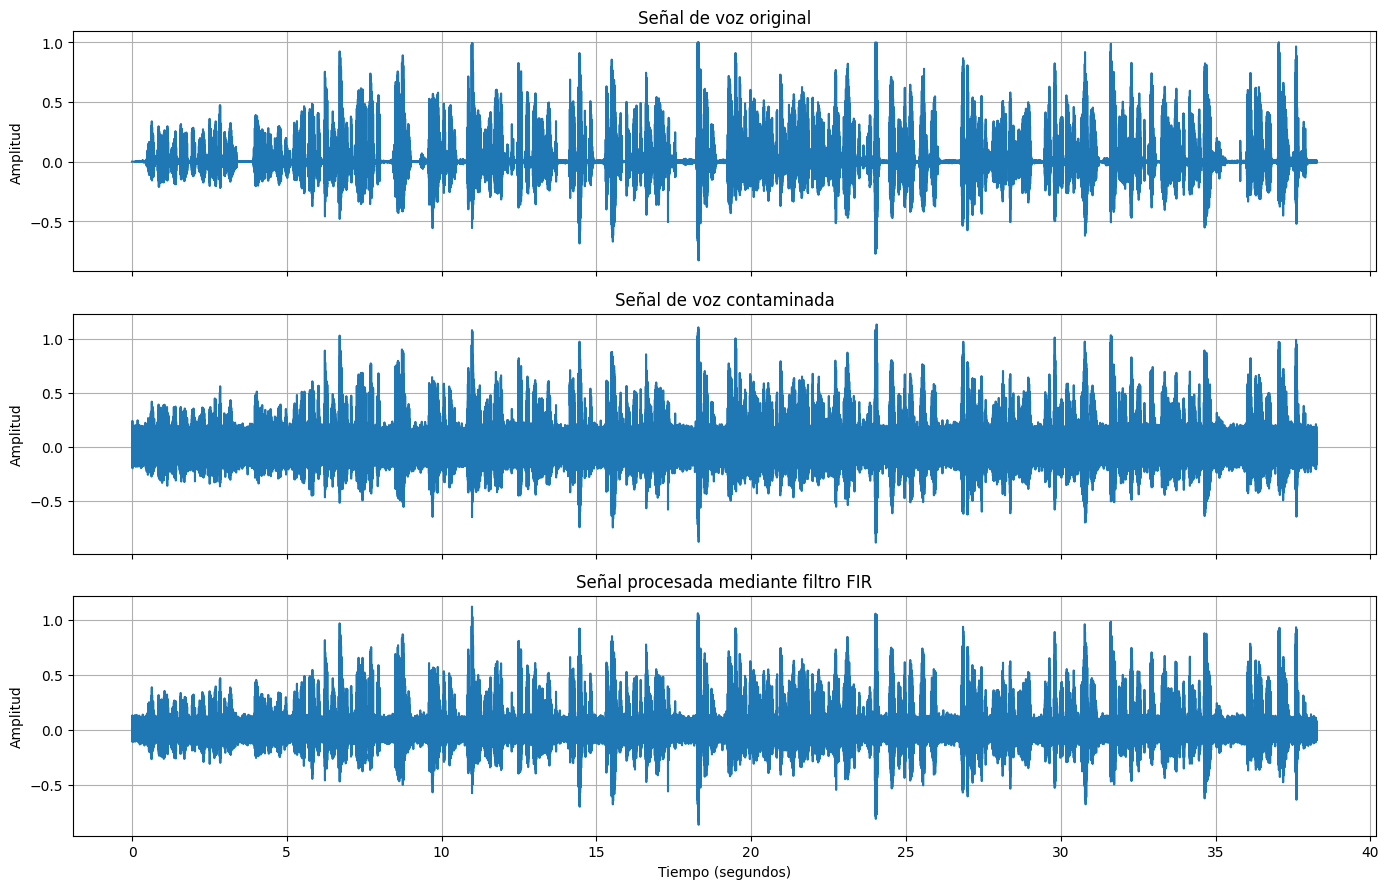

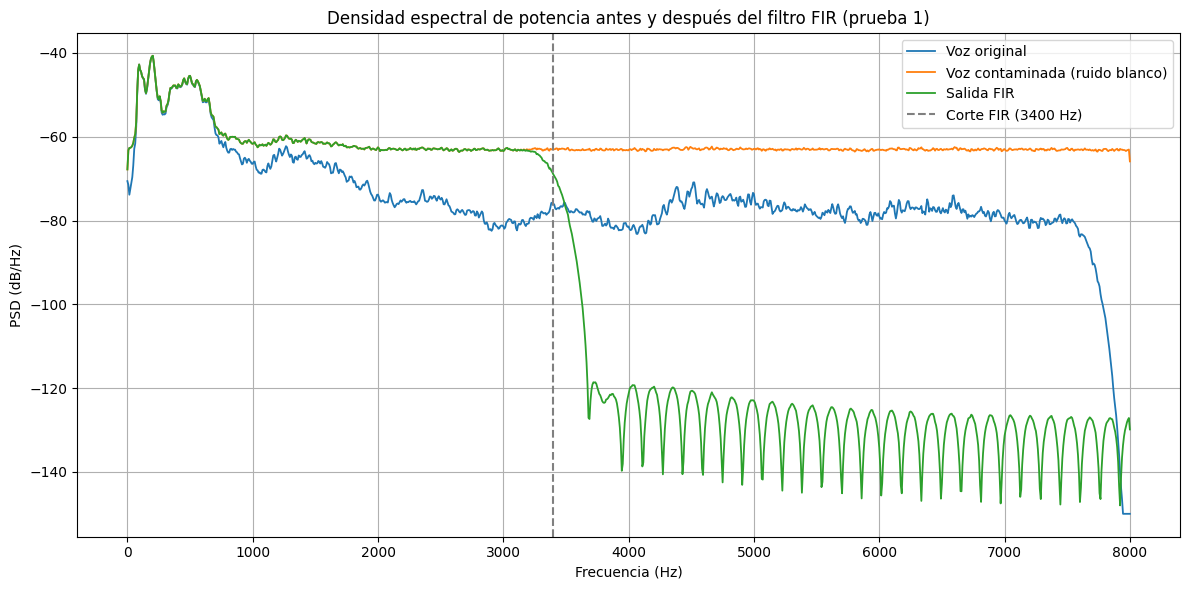


========== AJUSTE DEL PASO DE ADAPTACIÓN LMS ==========
c = 0.5   mu = 10.6994 | SNR in 5.09 | SNR out 4.80 | Mejora -0.29 dB | MSE in 0.003834 | MSE out 0.004097
c = 0.05  mu = 1.0699 | SNR in 5.09 | SNR out 16.23 | Mejora 11.14 dB | MSE in 0.003834 | MSE out 0.000295

 COMPARACIÓN EXPERIMENTAL FIR VS. LMS (misma señal)
mu LMS = 1.0699442821947374 | evaluación: desde t = 1 s hasta N-50
--- FIR --- SNR in 5.09 | SNR out 6.28 | Mejora 1.19 dB | MSE in 0.003834 | MSE out 0.002913
--- LMS --- SNR in 5.09 | SNR out 16.23 | Mejora 11.14 dB | MSE in 0.003834 | MSE out 0.000295
Mayor mejora de SNR: LMS | Menor MSE: LMS

========== ¿COINCIDE CON LA CORRIDA ORIGINAL? ==========
FIR prueba 1 (SNR out): obtenido 8.61 | original 8.61 -> COINCIDE
FIR comparación (SNR out): obtenido 6.28 | original 6.28 -> COINCIDE
LMS comparación (SNR out): obtenido 16.23 | original 16.23 -> COINCIDE


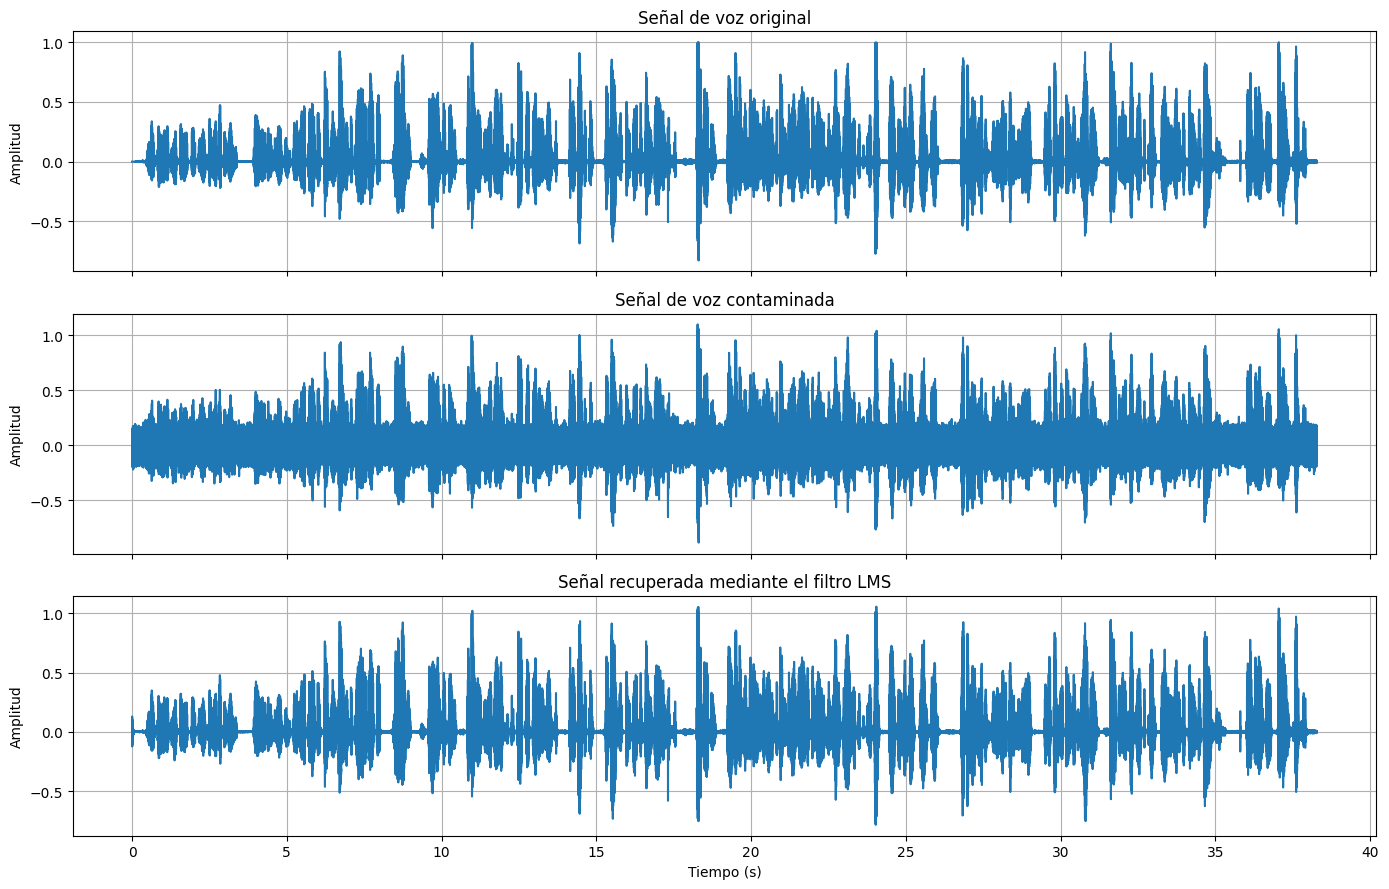

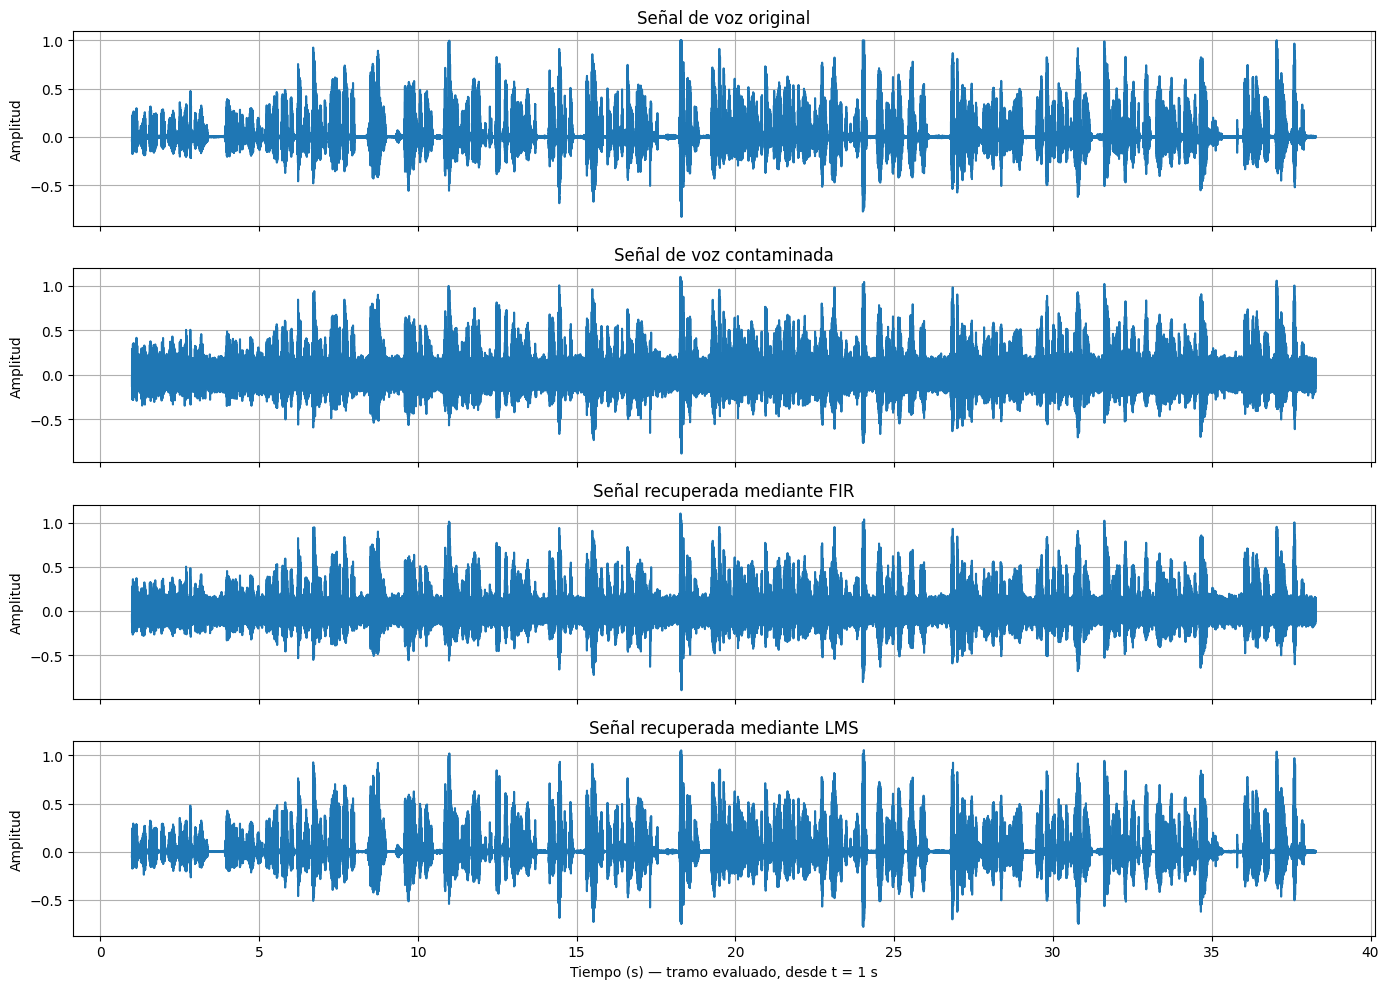

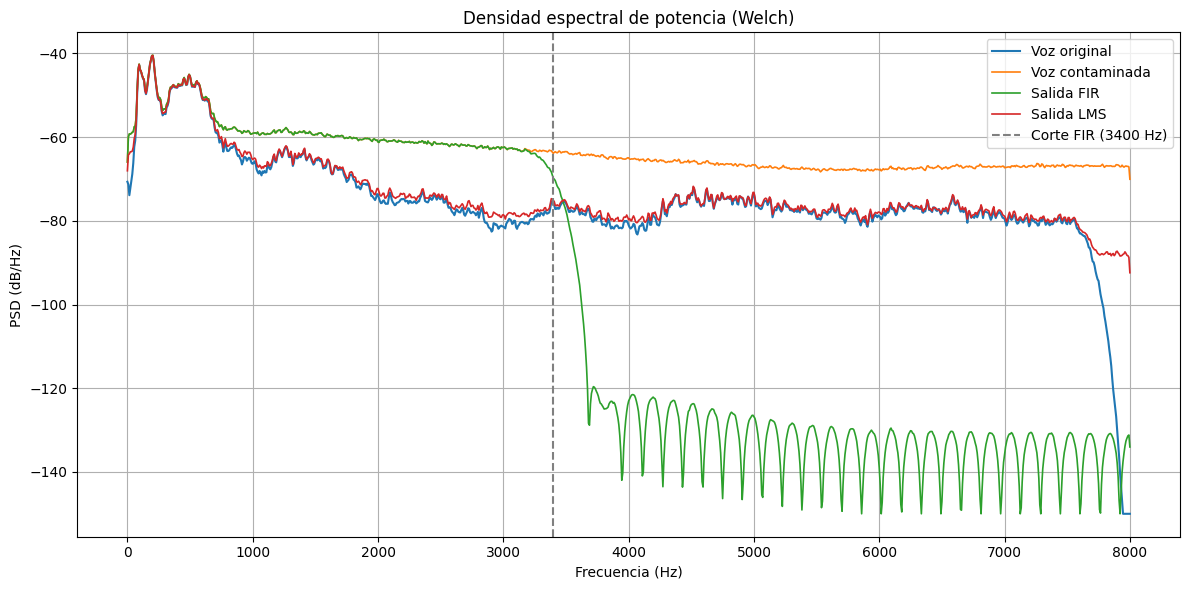

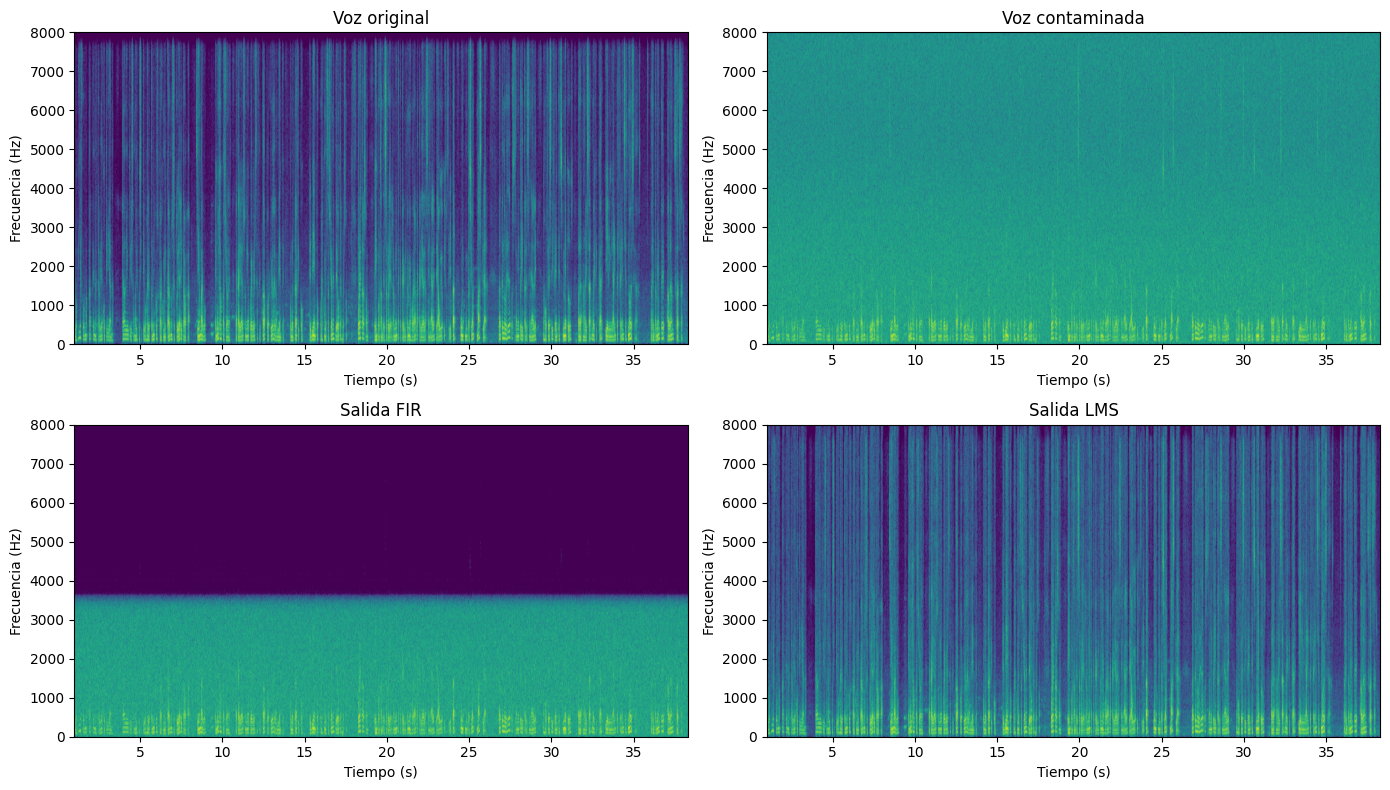


Archivos generados:
   portafolio/senales/audio_contaminado.wav
   portafolio/senales/audio_contaminado_LMS.wav
   portafolio/senales/audio_filtrado_FIR.wav
   portafolio/senales/audio_filtrado_LMS.wav
   portafolio/senales/audio_original.wav
   portafolio/senales/comparacion_FIR.wav
   portafolio/senales/comparacion_LMS.wav
   portafolio/evidencias/01_senal_original.png
   portafolio/evidencias/02_original_vs_contaminada.png
   portafolio/evidencias/03_FIR_respuesta_frecuencia.png
   portafolio/evidencias/04_FIR_temporal.png
   portafolio/evidencias/05_FIR_espectro_antes_despues.png
   portafolio/evidencias/06_LMS_temporal.png
   portafolio/evidencias/07_comparacion_temporal_FIR_LMS.png
   portafolio/evidencias/08_comparacion_espectro_PSD.png
   portafolio/evidencias/09_comparacion_espectrogramas.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# -*- coding: utf-8 -*-
# ============================================================
# ACTIVIDAD SUMATIVA N.º 4 — EL FILTRO PERFECTO
# Diseño y evaluación comparativa de filtros FIR y adaptativos LMS
# para la eliminación de ruido en señales de audio de voz.
#
# Script COMPLETO y REPRODUCIBLE (semillas fijas):
#   1) Prepara el audio (48 kHz -> 16 kHz, mono, normalizado)
#   2) Prueba 1: ruido blanco gaussiano + filtro FIR (Hamming)
#   3) Prueba 2: cancelación adaptativa LMS y comparación FIR vs LMS
#   4) Genera todos los audios, gráficas y un ZIP con el portafolio
# Ejecutar en UNA sola celda de Google Colab.
# ============================================================
import os, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy import signal
try:
    import librosa
except ImportError:
    os.system("pip install -q librosa")
    import librosa

# ------------------------- PARÁMETROS -------------------------
FS = 16000            # frecuencia de trabajo (Hz)
SNR_DB = 5            # SNR inicial deseado (dB)
ORDEN_FIR = 100       # orden del FIR (101 coeficientes)
FC = 3400             # frecuencia de corte del FIR (Hz)
L_LMS = 16            # longitud del filtro LMS
C_MU = 0.05           # mu = C_MU / (L * potencia_referencia)
MEDIR_TIEMPOS = False # True = repite la medición de tiempos (Paso 6)
RUTA_AUDIO = None     # None = pedirá subir el archivo en Colab

SEN, EVI = "portafolio/senales/", "portafolio/evidencias/"
os.makedirs(SEN, exist_ok=True); os.makedirs(EVI, exist_ok=True)

def guardar(nombre):
    plt.tight_layout(); plt.savefig(EVI + nombre, dpi=200); plt.show()

def metricas(ref, ent, sal):
    """SNR y MSE respecto a la señal original (mismas muestras)."""
    e_in, e_out = ent - ref, sal - ref
    snr_in = 10 * np.log10(np.mean(ref**2) / np.mean(e_in**2))
    snr_out = 10 * np.log10(np.mean(ref**2) / np.mean(e_out**2))
    return snr_in, snr_out, snr_out - snr_in, np.mean(e_in**2), np.mean(e_out**2)

def lms(ref, d, L, mu):
    """Cancelador adaptativo LMS: salida = e[n] = d[n] - y[n]."""
    w = np.zeros(L)
    out = np.zeros(len(d))
    for n in range(L - 1, len(d)):
        x = ref[n - L + 1:n + 1][::-1]
        y = np.dot(w, x)
        e = d[n] - y
        w += mu * e * x
        out[n] = e
    return out

def psd_db(x):
    f, p = signal.welch(x, fs=FS, nperseg=2048)
    return f, 10 * np.log10(np.maximum(p, 1e-15))

# ======================== 1. AUDIO ========================
if RUTA_AUDIO is None:
    from google.colab import files
    subido = files.upload()
    RUTA_AUDIO = next(iter(subido))
audio, fs_orig = librosa.load(RUTA_AUDIO, sr=None, mono=True)
audio = librosa.resample(audio, orig_sr=fs_orig, target_sr=FS)
audio = audio / np.max(np.abs(audio))
N = len(audio)
sf.write(SEN + "audio_original.wav", audio, FS)
print("========== AUDIO ==========")
print("Archivo:", RUTA_AUDIO, "| fs original:", fs_orig, "Hz | fs trabajo:", FS, "Hz")
print("Duración:", round(N / FS, 4), "s | Muestras:", N, "(original: 612376)")

t = np.arange(N) / FS
plt.figure(figsize=(14, 4)); plt.plot(t, audio)
plt.title("Señal de audio original"); plt.xlabel("Tiempo (segundos)"); plt.ylabel("Amplitud"); plt.grid(True)
guardar("01_senal_original.png")

# ================= 2. PRUEBA 1: RUIDO BLANCO + FIR =================
np.random.seed(42)
pot_ruido = np.mean(audio**2) / (10 ** (SNR_DB / 10))
ruido_A = np.random.normal(0, np.sqrt(pot_ruido), N)
cont_A = audio + ruido_A
sf.write(SEN + "audio_contaminado.wav", cont_A, FS)
print("\n========== RUIDO BLANCO GAUSSIANO (prueba 1) ==========")
print("SNR real de entrada:", round(10*np.log10(np.mean(audio**2)/np.mean(ruido_A**2)), 2), "dB")
print("MSE inicial:", round(np.mean((audio - cont_A)**2), 6))

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax[0].plot(t, audio); ax[0].set_title("Señal de voz original")
ax[1].plot(t, cont_A); ax[1].set_title("Señal de voz contaminada con ruido blanco gaussiano")
for a in ax: a.set_ylabel("Amplitud"); a.grid(True)
ax[1].set_xlabel("Tiempo (segundos)")
guardar("02_original_vs_contaminada.png")

h = signal.firwin(numtaps=ORDEN_FIR + 1, cutoff=FC, window="hamming", pass_zero="lowpass", fs=FS)
ret = ORDEN_FIR // 2
fir_A = signal.lfilter(h, [1.0], cont_A)
ref_A, ent_A, sal_A = audio[:-ret], cont_A[:-ret], fir_A[ret:]
mA = metricas(ref_A, ent_A, sal_A)
sf.write(SEN + "audio_filtrado_FIR.wav", sal_A, FS)
print("\n========== FILTRO FIR (prueba 1) ==========")
print(f"Orden {ORDEN_FIR} | {ORDEN_FIR+1} coef. | Hamming | fc {FC} Hz | retardo {ret} muestras")
print(f"SNR entrada: {mA[0]:.2f} dB | SNR salida: {mA[1]:.2f} dB | Mejora: {mA[2]:.2f} dB")
print(f"MSE entrada: {mA[3]:.6f} | MSE salida: {mA[4]:.6f}")

w, H = signal.freqz(h, worN=4096, fs=FS)
plt.figure(figsize=(12, 4.5)); plt.plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-10)))
plt.axvline(FC, color="gray", linestyle="--", label="Frecuencia de corte (3.400 Hz)")
plt.title("Respuesta en frecuencia del filtro FIR Hamming (orden 100)")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Magnitud (dB)")
plt.xlim(0, 8000); plt.ylim(-120, 5); plt.grid(True); plt.legend()
guardar("03_FIR_respuesta_frecuencia.png")

tA = np.arange(len(sal_A)) / FS
fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for a, x, ti in zip(ax, [ref_A, ent_A, sal_A],
        ["Señal de voz original", "Señal de voz contaminada", "Señal procesada mediante filtro FIR"]):
    a.plot(tA, x); a.set_title(ti); a.set_ylabel("Amplitud"); a.grid(True)
ax[-1].set_xlabel("Tiempo (segundos)")
guardar("04_FIR_temporal.png")

plt.figure(figsize=(12, 6))
for x, lab in [(ref_A, "Voz original"), (ent_A, "Voz contaminada (ruido blanco)"), (sal_A, "Salida FIR")]:
    f_, p_ = psd_db(x); plt.plot(f_, p_, label=lab, linewidth=1.3)
plt.axvline(FC, color="gray", linestyle="--", label="Corte FIR (3400 Hz)")
plt.title("Densidad espectral de potencia antes y después del filtro FIR (prueba 1)")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD (dB/Hz)"); plt.legend(); plt.grid(True)
guardar("05_FIR_espectro_antes_despues.png")

# ============ 3. PRUEBA 2: LMS Y COMPARACIÓN EN IGUALDAD ============
rng = np.random.default_rng(123)
fuente = rng.normal(0, 1, N)
canal = [1.0, 0.5, 0.25]
ruido_sin = signal.lfilter(canal, [1.0], fuente)
factor = np.sqrt((np.mean(audio**2) / (10 ** (SNR_DB / 10))) / np.mean(ruido_sin**2))
ruido_B = ruido_sin * factor
ref_ruido = fuente * factor
cont_B = audio + ruido_B
pot_ref = np.mean(ref_ruido**2)
ini = FS

print("\n========== AJUSTE DEL PASO DE ADAPTACIÓN LMS ==========")
salidas = {}
for c in (0.5, C_MU):
    mu = c / (L_LMS * pot_ref)
    out = lms(ref_ruido, cont_B, L_LMS, mu)
    salidas[c] = out
    m = metricas(audio[ini:], cont_B[ini:], out[ini:])
    print(f"c = {c:<5} mu = {mu:.4f} | SNR in {m[0]:.2f} | SNR out {m[1]:.2f} | Mejora {m[2]:.2f} dB | "
          f"MSE in {m[3]:.6f} | MSE out {m[4]:.6f}")
mu_final = C_MU / (L_LMS * pot_ref)
lms_out = salidas[C_MU]
sf.write(SEN + "audio_filtrado_LMS.wav", lms_out, FS)
sf.write(SEN + "audio_contaminado_LMS.wav", cont_B, FS)

fir_B = signal.lfilter(h, [1.0], cont_B)
fin = N - ret
v_ref, v_ent = audio[ini:fin], cont_B[ini:fin]
s_fir, s_lms = fir_B[ini + ret:fin + ret], lms_out[ini:fin]
mF, mL = metricas(v_ref, v_ent, s_fir), metricas(v_ref, v_ent, s_lms)
sf.write(SEN + "comparacion_FIR.wav", s_fir, FS)
sf.write(SEN + "comparacion_LMS.wav", s_lms, FS)

print("\n==============================================")
print(" COMPARACIÓN EXPERIMENTAL FIR VS. LMS (misma señal)")
print("==============================================")
print(f"mu LMS = {mu_final} | evaluación: desde t = 1 s hasta N-{ret}")
for nombre, m in (("FIR", mF), ("LMS", mL)):
    print(f"--- {nombre} --- SNR in {m[0]:.2f} | SNR out {m[1]:.2f} | Mejora {m[2]:.2f} dB | "
          f"MSE in {m[3]:.6f} | MSE out {m[4]:.6f}")
print("Mayor mejora de SNR:", "LMS" if mL[2] > mF[2] else "FIR", "| Menor MSE:", "LMS" if mL[4] < mF[4] else "FIR")

# ---- verificación contra la corrida original ----
esperado = {"FIR prueba 1 (SNR out)": (mA[1], 8.61), "FIR comparación (SNR out)": (mF[1], 6.28),
            "LMS comparación (SNR out)": (mL[1], 16.23)}
print("\n========== ¿COINCIDE CON LA CORRIDA ORIGINAL? ==========")
for k, (obt, esp) in esperado.items():
    print(f"{k}: obtenido {obt:.2f} | original {esp} ->", "COINCIDE" if abs(obt - esp) <= 0.02 else "DIFIERE")

# ---- gráficas de la prueba 2 ----
tL = np.arange(N) / FS
fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for a, x, ti in zip(ax, [audio, cont_B, lms_out],
        ["Señal de voz original", "Señal de voz contaminada", "Señal recuperada mediante el filtro LMS"]):
    a.plot(tL, x); a.set_title(ti); a.set_ylabel("Amplitud"); a.grid(True)
ax[-1].set_xlabel("Tiempo (s)")
guardar("06_LMS_temporal.png")

tc = ini / FS + np.arange(len(v_ref)) / FS     # eje de tiempo real (desde t = 1 s)
fig, ax = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for a, x, ti in zip(ax, [v_ref, v_ent, s_fir, s_lms],
        ["Señal de voz original", "Señal de voz contaminada",
         "Señal recuperada mediante FIR", "Señal recuperada mediante LMS"]):
    a.plot(tc, x); a.set_title(ti); a.set_ylabel("Amplitud"); a.grid(True)
ax[-1].set_xlabel("Tiempo (s) — tramo evaluado, desde t = 1 s")
guardar("07_comparacion_temporal_FIR_LMS.png")

plt.figure(figsize=(12, 6))
for x, lab, lw in [(v_ref, "Voz original", 1.5), (v_ent, "Voz contaminada", 1.2),
                   (s_fir, "Salida FIR", 1.2), (s_lms, "Salida LMS", 1.2)]:
    f_, p_ = psd_db(x); plt.plot(f_, p_, label=lab, linewidth=lw)
plt.axvline(FC, color="gray", linestyle="--", label="Corte FIR (3400 Hz)")
plt.title("Densidad espectral de potencia (Welch)")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD (dB/Hz)"); plt.legend(); plt.grid(True)
guardar("08_comparacion_espectro_PSD.png")

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for a, (x, ti) in zip(ax.ravel(), [(v_ref, "Voz original"), (v_ent, "Voz contaminada"),
                                   (s_fir, "Salida FIR"), (s_lms, "Salida LMS")]):
    a.specgram(x, NFFT=512, Fs=FS, noverlap=256, cmap="viridis", vmin=-120, vmax=-20,
               xextent=(ini / FS, ini / FS + len(x) / FS))
    a.set_title(ti); a.set_xlabel("Tiempo (s)"); a.set_ylabel("Frecuencia (Hz)")
guardar("09_comparacion_espectrogramas.png")

# ================= 4. COMPLEJIDAD (opcional) =================
if MEDIR_TIEMPOS:
    t_fir, t_lms = [], []
    for _ in range(5):
        t0 = time.perf_counter(); signal.lfilter(h, [1.0], cont_B); t_fir.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); lms(ref_ruido, cont_B, L_LMS, mu_final); t_lms.append(time.perf_counter() - t0)
    print("\n========== COMPLEJIDAD COMPUTACIONAL ==========")
    print(f"FIR: {np.mean(t_fir):.4f} s (desv. {np.std(t_fir):.4f}) | {ORDEN_FIR+1} mult./muestra")
    print(f"LMS: {np.mean(t_lms):.4f} s (desv. {np.std(t_lms):.4f}) | ~{2*L_LMS+1} mult./muestra")
    print(f"Relación LMS/FIR: {np.mean(t_lms)/np.mean(t_fir):.1f}x")

# ======================= 5. EMPAQUETAR =======================
shutil.make_archive("portafolio_evidencias", "zip", "portafolio")
print("\nArchivos generados:")
for carpeta in (SEN, EVI):
    for f in sorted(os.listdir(carpeta)): print("  ", carpeta + f)
try:
    from google.colab import files
    files.download("portafolio_evidencias.zip")
except ImportError:
    pass